# El plan de capital: ingreso neto antes de provisiones, la trayectoria de CET1, el balance estático de la EBA y la pila de capital chilena

**Pregunta:** Bajo el escenario severamente adverso de la Reserva Federal, ¿mantiene Banco Andino su patrimonio efectivo sobre
el mínimo legal en cada uno de los tres años, y sobre su propio objetivo interno de capital?

- **Nivel:** 2, El método en la práctica
- **Requisitos previos:** el notebook 04 de este tema (los escenarios y las tasas de pérdida que implican)
- **Tiempo de lectura:** unos 60 minutos

## Objetivos

Al terminar este notebook puedes:

- construir la trayectoria de CET1 titular de un estrés como el CET1 inicial menos las pérdidas estresadas acumuladas, y decir
  por qué no se inventa ningún ingreso en ella;
- añadir la fila etiquetada de ingreso neto antes de provisiones con dos razones declaradas y ver cuánto levanta la razón;
- construir el objetivo interno de capital y el mínimo legal del marco IAPE chileno, y ver al motor rechazar un requerimiento
  sobre el tope de 4 por ciento y una estimación propia bajo el requerimiento;
- ejecutar los tres casos del plan de capital sobre un balance estático, y leer la diferencia entre mantener el mínimo legal y
  mantener el objetivo propio del banco;
- aplicar la regla de etapa 3 de la EBA, plantar una violación y ver al motor nombrarla, y reconstruir las 34 filas del
  formulario del Anexo 3.

## Preparación

Instala una vez el entorno fijado, en un entorno virtual, con el comando de siempre:

```bash
pip install -r notebooks/requirements.txt
```

o solo los paquetes que usa este notebook, con las mismas versiones exactas:

```bash
pip install riskvalidation==1.0.1 numpy==2.4.6 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` en Windows) construye `.venv-notebooks` por ti. Un notebook nunca instala nada por sí mismo. Los identificadores de las pruebas del motor se imprimen tal como los escribe el motor. Sus mensajes y notas están escritos en inglés: el árbol inglés los imprime como están, y este árbol imprime una traducción desde una tabla del notebook que falla si el motor cambia el texto.

Este notebook lee además un archivo de constantes del flujo de generación del producto, `data-pipeline/pipeline/cases/c18/params.py` (la asignación de los seis segmentos de C07 a las tres clases de préstamo). El flujo de generación es un conjunto de scripts y no un paquete, así que el notebook carga ese único archivo por su ruta con la biblioteca estándar: una sola fuente para la asignación, nunca una copia. El archivo no tiene dependencias.

La celda siguiente importa lo que usa el notebook e imprime las versiones de los paquetes, para que las compares con las fijadas.

In [1]:
# Importaciones, versiones y lectores; la carpeta del flujo de generación va en la ruta porque nunca se instala
import importlib.metadata as md
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import riskvalidation as rv
from riskvalidation.stress import capital
from riskvalidation.validation import stress as stress_tests

for name in ("riskvalidation", "numpy", "matplotlib"):
    print(name, md.version(name))
ROOT = Path("../../..").resolve()
DERIVED = ROOT / "data" / "derived"
sys.path.insert(0, str(ROOT / "data-pipeline"))
from pipeline.cases.c18 import params as c18_params


def read_json(relative):
    return json.loads((DERIVED / relative).read_text(encoding="utf-8"))

riskvalidation 1.0.1
numpy 2.4.6
matplotlib 3.11.2


## Datos

Este notebook lee el lado de capital de **C18** (Banco Andino).

- **Propietario y licencia:** los documentos los escribe el flujo sin conexión de este repositorio (`data-pipeline/pipeline/cases/c18/`) con el motor `riskvalidation` y se versionan en `data/derived/C18/`. Las trayectorias de escenario vienen de la Reserva Federal (dominio público), de la EBA y la ESRB (reproducción autorizada citando la fuente) y de la NGFS (solo derivado: únicamente las pocas variables que usa el caso). **Banco Andino es un banco sintético**: su cartera y su capital están calibrados a agregados públicos, y las trayectorias son trayectorias reales de Estados Unidos y de la zona euro trasladadas a su punto de partida, así que los satélites son una adaptación calibrada en EE. UU.
- **Estatus de verdad:** `synthetic-calibrated`. No hay respuesta publicada para el banco; las verificaciones de este notebook son recálculos de números versionados con el motor, no comparaciones con un resultado publicado.
- **Horneado con:** `riskvalidation` 0.8.1 (semilla 42), la versión que instala este notebook, así que se espera que un recálculo coincida hasta el redondeo.
- **Archivos leídos:** `data/derived/C18/baseline.json` y `fed-2026-severely-adverse.json` (`outputs.capital_start`, `losses`, `internal_capital_target`, `headline_cet1`, `capital_plan`, `p2g_proxy`, `annex3`), el documento de modelos `models-banco-andino.json` (la pila chilena, las reglas de la EBA por párrafo), `reverse-stress.json` (la pila del punto de falla) y, para el balance estático, los saldos por etapa y los parámetros de segmento del caso de provisiones C07 (`data/derived/C07/base.json` y `models-banco-andino.json`) y la asignación de segmento a clase de `data-pipeline/pipeline/cases/c18/params.py`.
- **El capital de Banco Andino es un ancla, no un balance.** El CET1 es el aproximación de Tier 1 del caso de tasas C15; los activos ponderados por riesgo (APR) son ese aproximación sobre el ancla de CET1 de 11,0 por ciento, repartidos entre riesgo de crédito, de mercado y operacional según la mezcla del Formulario 20-F 2025 de un banco chileno grande (solo razones, porque el documento es solo derivado). La parte del patrimonio efectivo sobre el CET1 se lleva como Tier 2 y el AT1 es nulo, un supuesto **NO VERIFICADO** en las fuentes y rotulado así en el documento. El dinero está en millones de CLP y las proporciones son proporciones de los APR.

In [2]:
# Los documentos de capital base y severamente adverso, el documento de modelos y el capital del punto de
# partida
baseline = read_json("C18/baseline.json")["outputs"]
fed_doc = read_json("C18/fed-2026-severely-adverse.json")
fed = fed_doc["outputs"]
models = read_json("C18/models-banco-andino.json")["fit"]
start = fed["capital_start"]
YEARS = ["1", "2", "3"]
print("punto de partida", fed["bank"]["as_of"])
print("RWA", round(start["rwa_clp_m"], 1), "CET1", round(start["cet1_clp_m"], 1))
print("razón CET1 y razón de patrimonio efectivo", start["cet1_ratio"], round(start["pe_ratio"], 6))

punto de partida 2026-08-31
RWA 7492853.0 CET1 824213.8
razón CET1 y razón de patrimonio efectivo 0.11 0.168938


## Método

### Paso 1: la trayectoria principal, el CET1 menos las pérdidas

La trayectoria de CET1 **principal** del caso es el **agotamiento de solo pérdidas**: el CET1 del punto de partida menos las pérdidas con estrés acumuladas de los años transcurridos, sin inventar ingresos,

$$\mathrm{CET1}_y = \mathrm{CET1}_0 - \sum_{s \le y} L_s, \qquad y = 1, 2, 3.$$

La pérdida de un año es la suma de la pérdida de crédito del notebook 04 y las pérdidas esperadas de los demás riesgos: mercado y riesgo operacional no tienen libro de posiciones ni mapa macro en el caso, así que cada uno lleva su pérdida esperada anual en todo escenario y la pérdida con estrés es un piso. La pérdida de IRRBB es nula porque un cambio de valor económico no es una partida de resultados de la cartera de inversión; la trayectoria de tasas actúa en cambio sobre el margen financiero neto (paso 2). `cet1_path_loss_only(cet1_0, losses)` calcula la trayectoria.

La celda siguiente lee las pérdidas del escenario severamente adverso, construye la trayectoria con `cet1_path_loss_only` y
dibuja la pérdida estresada de cada año, por riesgo de crédito y operacional, con la razón CET1 que resulta.

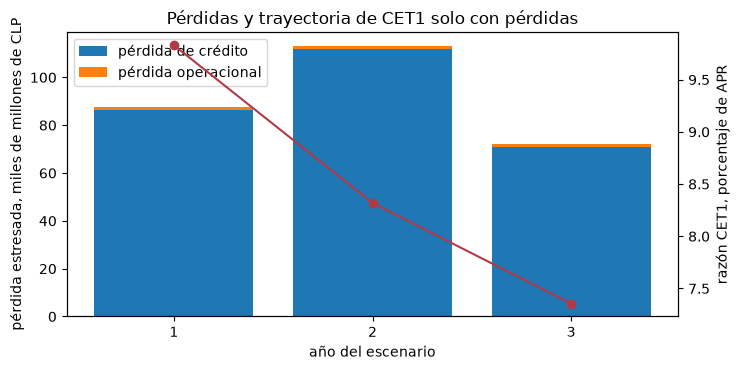

pérdidas estresadas, millones de CLP [87706, 113174, 72193]
trayectoria de CET1, millones de CLP [736507.7 623333.4 551140.8]
razón CET1, porcentaje de APR [9.83 8.32 7.36]
razón CET1 en el punto de partida, porcentaje 11.0


In [3]:
# La trayectoria de CET1 solo con pérdidas del escenario severamente adverso y las pérdidas que la causan
loss_rows = fed["losses"]["scenario_losses"]
losses = [row["total"] for row in loss_rows]
path = capital.cet1_path_loss_only(start["cet1_clp_m"], losses)
ratio = path / start["rwa_clp_m"]
fig, ax = plt.subplots(figsize=(7.5, 3.8))
bottom = np.zeros(3)
for part, label in (("credit", "pérdida de crédito"), ("operational", "pérdida operacional")):
    values = np.array([row[part] for row in loss_rows]) / 1e3
    ax.bar(YEARS, values, bottom=bottom, label=label)
    bottom += values
ax.set_xlabel("año del escenario")
ax.set_ylabel("pérdida estresada, miles de millones de CLP")
ax.legend(loc="upper left")
twin = ax.twinx()
twin.plot(YEARS, ratio * 100, "o-", color="#b23a48")
twin.set_ylabel("razón CET1, porcentaje de APR")
ax.set_title("Pérdidas y trayectoria de CET1 solo con pérdidas")
fig.tight_layout()
plt.show()
print("pérdidas estresadas, millones de CLP", [round(v) for v in losses])
print("trayectoria de CET1, millones de CLP", np.round(path, 1))
print("razón CET1, porcentaje de APR", np.round(ratio * 100, 2))
print("razón CET1 en el punto de partida, porcentaje", round(start["cet1_ratio"] * 100, 2))

Las barras son casi todo pérdida de crédito, 86.519; 111.987 y 71.005 millones de pesos, porque los riesgos de mercado y
operacional llevan solo su pérdida esperada en todo escenario, 1.188 millones el operacional y nada el de mercado, así que la
pérdida estresada es un piso. La línea roja es la razón CET1 que resulta: 11,00 por ciento de los APR en el punto de partida cae
a 9,83; 8,32 y 7,36 por ciento. No se suma nada de vuelta, a propósito, porque un titular que contara ingresos que el banco
aún no gana halagaría la razón.

### Paso 2: la fila rotulada de PPNR

Un banco gana mientras pierde. El caso agrega una **fila rotulada** con el ingreso neto antes de provisiones, nunca el capital principal. El margen financiero neto (NII) de cada año sigue la trayectoria de tasas del escenario a través del motor de tasas de interés del tema 09 sobre la cartera de C15; los ingresos por comisiones y el costo operacional son dos razones constantes declaradas, supuestos del caso y no cifras de Banco Andino ni de la CMF:

$$\text{comisiones} = r_{\text{com}}\cdot\mathrm{NII},\qquad \text{costo} = r_{\text{costo}}\,(\mathrm{NII} + \text{comisiones}),\qquad \mathrm{PPNR} = \mathrm{NII} + \text{comisiones} - \text{costo},$$

con $r_{\text{com}} = 0,25$ y $r_{\text{costo}} = 0,55$. Los dossiers no documentan un modelo de PPNR de la Reserva Federal; su elemento de razón de eficiencia es solo el precedente de una razón de costo. `ppnr_row(nii, fee_ratio, cost_ratio)` calcula la fila.

La celda siguiente llama a `ppnr_row` para cada año con el margen financiero neto versionado y las dos razones declaradas,
suma el PPNR acumulado a la trayectoria solo con pérdidas y dibuja los componentes de la fila junto a la razón CET1 con y sin
él.

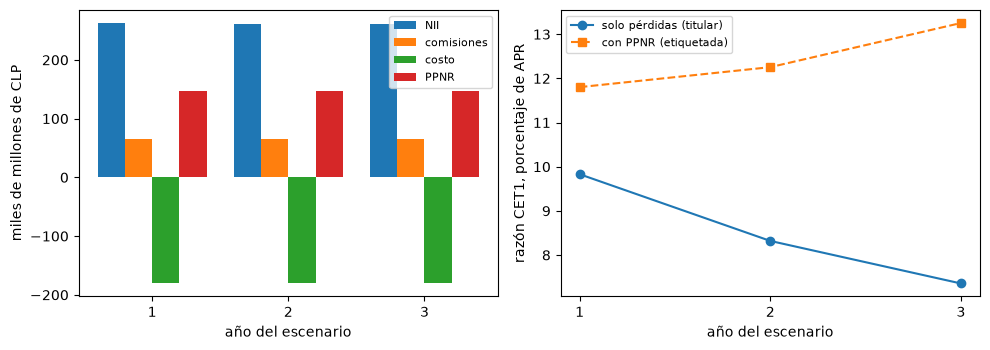

NII, comisiones, costo, PPNR del año 1 [262778, 65695, 180660, 147813]
PPNR por año [147813, 147070, 147070]
razón CET1 con PPNR [11.8  12.25 13.25]


In [4]:
# La fila etiquetada de PPNR de cada año desde el NII versionado y las dos razones declaradas, y el CET1 con
# PPNR
ppnr = fed["headline_cet1"]["ppnr"]
fee_ratio, cost_ratio = ppnr["fee_ratio"]["value"], ppnr["cost_ratio"]["value"]
rows = [capital.ppnr_row(r["nii_clp_m"], fee_ratio, cost_ratio) for r in ppnr["rows"]]
with_ppnr = path + np.cumsum([r.ppnr for r in rows])
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
width = 0.2
for k, (label, values) in enumerate((("NII", [r.nii for r in rows]), ("comisiones", [r.fee_income for r in rows]),
                                     ("costo", [-r.operating_cost for r in rows]), ("PPNR", [r.ppnr for r in rows]))):
    axes[0].bar(np.arange(3) + (k - 1.5) * width, np.array(values) / 1e3, width=width, label=label)
axes[0].set_xticks(np.arange(3))
axes[0].set_xticklabels(YEARS)
axes[0].set_ylabel("miles de millones de CLP")
axes[0].legend(fontsize=8)
axes[1].plot(YEARS, ratio * 100, "o-", label="solo pérdidas (titular)")
axes[1].plot(YEARS, with_ppnr / start["rwa_clp_m"] * 100, "s--", label="con PPNR (etiquetada)")
axes[1].set_ylabel("razón CET1, porcentaje de APR")
axes[1].legend(fontsize=8)
for ax in axes:
    ax.set_xlabel("año del escenario")
fig.tight_layout()
plt.show()
year1 = (rows[0].nii, rows[0].fee_income, rows[0].operating_cost, rows[0].ppnr)
print("NII, comisiones, costo, PPNR del año 1", [round(v) for v in year1])
print("PPNR por año", [round(r.ppnr) for r in rows])
print("razón CET1 con PPNR", np.round(with_ppnr / start["rwa_clp_m"] * 100, 2))

La fila etiquetada agrega cerca de 147.000 millones de pesos al año (147.813 y luego 147.070 dos veces), que es un NII de
262.778 millones más 25 por ciento en comisiones menos 55 por ciento del total en costos. Levanta la razón CET1 a 11,80; 12,25
y 13,25 por ciento, más que el 11,00 inicial, y por eso la fila es una etiqueta y no el titular: un banco estresado que termina
sobre donde empezó apoya su respuesta en dos razones que el caso supone y en una trayectoria de tasas, ninguna de ellas una
predicción. El panel derecho hace visible la distancia entre las dos lecturas del mismo escenario.

### Paso 3: el objetivo interno de capital y el mínimo legal

En el marco IAPE de Chile (CMF RAN 21-13, Capítulo 21-13 sección I; dossier 03) un banco fija un **objetivo interno** de patrimonio efectivo sobre APR,

$$\mathrm{OI} \;\ge\; 8\% + c_{\mathrm{DSIB}} + c_{P2} + c_{\mathrm{CCoB}} + c_{\mathrm{CCyB}} + c_d,$$

el mínimo de 8 por ciento más el colchón de banco sistémico, la estimación propia del banco de Pilar 2, los colchones de conservación y contracíclico y un colchón voluntario de estrés $c_d$ (que puede ser cero). El término de Pilar 2 tiene dos cosas distintas: el **requerimiento del artículo 66 quinquies** $p2r$, que fija la CMF y que la ley limita a **4 por ciento de los APR**, y la estimación propia del banco $c_{P2} \ge p2r$, que no tiene tope. `internal_capital_target` del motor hace cumplir ambos hechos. El mínimo legal frente al que se prueba el estrés es $8\% + c_{\mathrm{DSIB}} + p2r$.

La celda siguiente construye el objetivo con `internal_capital_target` a partir de los componentes versionados y lo dibuja
como una pila junto al mínimo legal; luego ofrece al motor un requerimiento sobre el tope y una estimación propia bajo el
requerimiento, y calcula `chilean_cet1_stack`, el CET1 mínimo sobre APR de la pila legal, con la parte que usa el estrés
inverso del notebook 06.

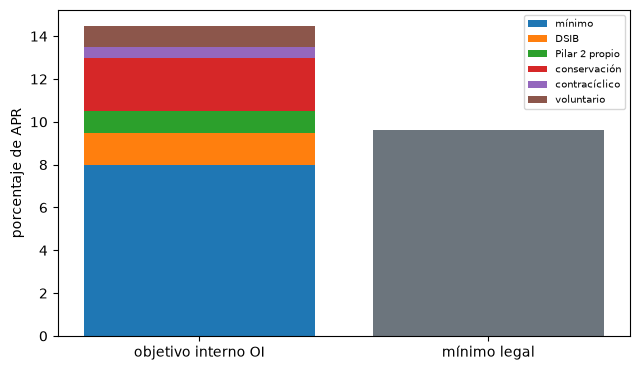

porcentaje de APR: OI 14.5 mínimo legal 9.625
p2r (art. 66 quinquies), porcentaje 0.125
p2r sobre el tope de 4 por ciento : rechazada
estimación propia bajo p2r : rechazada
pila de CET1 con la parte del estrés inverso, porcentaje 9.0625


In [5]:
# El objetivo interno y el mínimo legal desde los componentes versionados, los dos rechazos y la pila de CET1
target = fed["internal_capital_target"]
stack = models["bank_anchors"]["chilean_stack"]
own, voluntary = target["c_p2"]["value"], target["c_d"]["value"]
buffers = (target["c_dsib"], own, target["c_ccob"], target["c_ccyb"], voluntary)
oi = capital.internal_capital_target(*buffers, p2r=stack["p2r"])
legal_minimum = oi.min_pe + oi.c_dsib + oi.p2r
parts = [("mínimo", oi.min_pe), ("DSIB", oi.c_dsib), ("Pilar 2 propio", oi.c_p2), ("conservación", oi.c_ccob),
         ("contracíclico", oi.c_ccyb), ("voluntario", oi.c_d)]
fig, ax = plt.subplots(figsize=(6.5, 3.8))
bottom = 0.0
for label, value in parts:
    ax.bar("objetivo interno OI", value * 100, bottom=bottom * 100, label=label)
    bottom += value
ax.bar("mínimo legal", legal_minimum * 100, color="#6c757d")
ax.set_ylabel("porcentaje de APR")
ax.legend(fontsize=7, loc="upper right")
fig.tight_layout()
plt.show()
print("porcentaje de APR: OI", round(oi.oi * 100, 3), "mínimo legal", round(legal_minimum * 100, 3))
print("p2r (art. 66 quinquies), porcentaje", round(oi.p2r * 100, 3))
for why, p2r, c_p2 in (("p2r sobre el tope de 4 por ciento", 0.05, 0.05), ("estimación propia bajo p2r", 0.02, 0.01)):
    try:
        capital.internal_capital_target(buffers[0], c_p2, *buffers[2:], p2r=p2r)
    except ValueError:
        print(why, ": rechazada")
reverse = read_json("C18/reverse-stress.json")["outputs"]["failure_point"]["stack"]
cet1_stack = capital.chilean_cet1_stack(reverse["c_ccyb"], reverse["c_dsib"], reverse["p2_cet1"]["value"])
print("pila de CET1 con la parte del estrés inverso, porcentaje", round(cet1_stack * 100, 4))

El objetivo interno se apila hasta 14,5 por ciento de los APR: el mínimo de 8 por ciento, 1,5 del colchón de banco sistémico,
1,0 de la estimación propia de Pilar 2, 2,5 de conservación, 0,5 contracíclico y un colchón voluntario de estrés de 1,0. El
mínimo legal, la barra gris, es mucho menor, 9,625 por ciento, porque conserva solo el mínimo, el colchón sistémico y el
requerimiento del artículo 66 quinquies de 0,125 por ciento, que fija la CMF y la ley limita a 4. El motor rechaza ambos
errores, un requerimiento sobre el tope y una estimación bajo el requerimiento. La pila de CET1 del estrés inverso resulta
9,0625.

### Paso 4: los tres casos del plan

`capital_plan(rwa, cet1_0, at1, t2, base_cet1, stress_losses, mitigation_effects, oi, legal_minimum)` devuelve, para tres años, los tres casos de la proyección IAPE (dossier 03):

- **base:** CET1 de la trayectoria base del llamador (el CET1 del escenario base con su PPNR), probado frente al objetivo interno OI;
- **estrés sin mitigación:** la trayectoria de solo pérdidas del paso 1, probada frente al mínimo legal;
- **estrés con mitigación:** la misma trayectoria más las acciones de mitigación acumuladas.

Bajo el **balance estático** de las reglas de la EBA los APR son los mismos cada año, el AT1 y el Tier 2 quedan en sus valores de partida, y no se permite ninguna medida de capital después de la fecha de referencia. Las fuentes no nombran ninguna acción de mitigación, así que el caso no supone ninguna (el caso con mitigación es igual al sin ella y la fila 10.2 del Anexo 3 no aplica). La holgura de un año es la razón de patrimonio efectivo menos el requerimiento, y el déficit es $\max(0, \text{requerimiento}\cdot\mathrm{APR} - \mathrm{PE})$.

La trayectoria base es el CET1 del escenario base con PPNR, que la celda siguiente reconstruye a partir de las filas de pérdidas y de PPNR del propio documento base antes de llamar al motor. Dibuja la razón de patrimonio efectivo de los tres casos frente a los dos requerimientos e imprime la razón estresada frente al **objetivo interno**, no solo al mínimo legal.

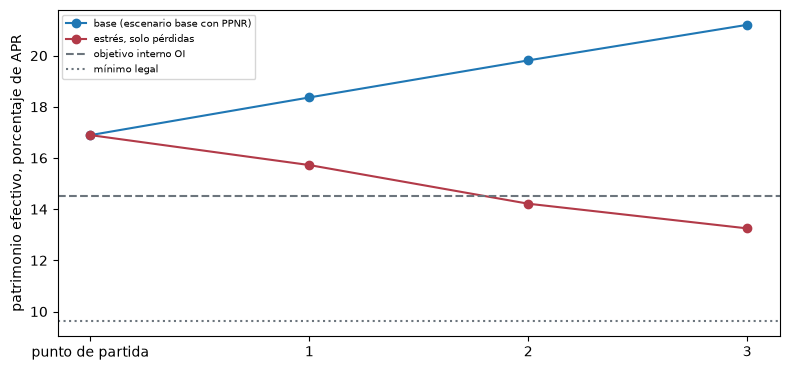

base                       [18.37, 19.81, 21.2] déficit [0, 0, 0]
stress-without-mitigation  [15.72, 14.21, 13.25] déficit [0, 0, 0]
stress-with-mitigation     [15.72, 14.21, 13.25] déficit [0, 0, 0]
estrés, patrimonio menos objetivo interno, puntos [1.22, -0.29, -1.25]


In [6]:
# Reconstruir la trayectoria base de CET1, ejecutar los tres casos del plan y dibujar las razones de patrimonio
# efectivo
base_rows = baseline["headline_cet1"]["ppnr"]["rows"]
base_losses = [row["total"] for row in baseline["losses"]["scenario_losses"]]
base_cet1 = start["cet1_clp_m"] + np.cumsum([r["ppnr_clp_m"] - loss for r, loss in zip(base_rows, base_losses)])
plan = capital.capital_plan(start["rwa_clp_m"], start["cet1_clp_m"], start["at1_clp_m"], start["t2_clp_m"],
                            base_cet1, losses, [0.0, 0.0, 0.0], oi.oi, legal_minimum)
stress = plan["stress-without-mitigation"]
x = np.arange(0, 4)
fig, ax = plt.subplots(figsize=(8, 3.8))
pe_base = [start["pe_ratio"] * 100] + [y.pe_pct * 100 for y in plan["base"]]
pe_stress = [start["pe_ratio"] * 100] + [y.pe_pct * 100 for y in stress]
ax.plot(x, pe_base, "o-", label="base (escenario base con PPNR)")
ax.plot(x, pe_stress, "o-", color="#b23a48", label="estrés, solo pérdidas")
ax.axhline(oi.oi * 100, color="#6c757d", linestyle="--", label="objetivo interno OI")
ax.axhline(legal_minimum * 100, color="#6c757d", linestyle=":", label="mínimo legal")
ax.set_xticks(x)
ax.set_xticklabels(["punto de partida"] + [f"{k}" for k in (1, 2, 3)])
ax.set_ylabel("patrimonio efectivo, porcentaje de APR")
ax.legend(fontsize=7, loc="upper left")
fig.tight_layout()
plt.show()
for case, years in plan.items():
    print(f"{case:26s}", [round(y.pe_pct * 100, 2) for y in years], "déficit", [round(y.deficit) for y in years])
print("estrés, patrimonio menos objetivo interno, puntos",
      [round((y.pe_pct - oi.oi) * 100, 2) for y in stress])

El mínimo legal se mantiene en todos los años del escenario severamente adverso, con la razón de patrimonio efectivo estresada
en 15,72; 14,21 y 13,25 por ciento frente a 9,625 y un déficit de cero. El objetivo interno es otro asunto: la razón queda 1,22
puntos sobre el objetivo de 14,5 por ciento en el primer año y 0,29 y 1,25 puntos bajo él en el segundo y el tercero.
**Mantener el mínimo legal y no cumplir el objetivo propio del banco son dos hallazgos distintos**, uno de solvencia bajo la
regulación y otro de si el apetito de riesgo del banco sobrevive al escenario. El caso con mitigación es igual al sin ella
porque las fuentes no nombran ninguna acción, y el caso base queda de 3,9 a 6,7 puntos sobre el objetivo.

### Paso 5: las reglas de balance estático de la EBA

La nota metodológica de la EBA 2025 (párrafos 33, 34 y 90 a 92) fija el balance durante el estrés: la exposición total es
constante, las exposiciones que vencen se reemplazan por otras similares, **las nuevas exposiciones de etapa 3 pasan al stock de
etapa 3 y nada sale de él** (sin curas, castigos ni bajas en los tres años), y los deterioros se calculan sobre un balance
constante. `eba_static_balance_sheet(stage_balances, new_s3_flows)` aplica la regla de la etapa 3: la nueva exposición de etapa
3 de cada período sale de las etapas 1 y 2 en proporción a sus saldos y se suma a la etapa 3. La primera de las dos celdas
siguientes construye los doce flujos trimestrales de nueva exposición de etapa 3, el monto de castigo trimestral sobre la
pérdida dado el incumplimiento de la clase, a partir de las tasas de los satélites y del caso de provisiones C07, con el mapa
de segmento a clase de `params.py` del flujo de generación.

In [7]:
# El mapa de segmento a clase del flujo de generación, los saldos por etapa de C07 y los flujos trimestrales
# nuevos de etapa 3
c07 = read_json("C07/base.json")["outputs"]
c07_fit = {s["segment_id"]: s for s in read_json("C07/models-banco-andino.json")["fit"]["ifrs9"]["segments"]}
exposure, lgd_weighted = {}, {}
for segment in c07["portfolio"]["segments"]:
    klass = c18_params.SEGMENT_CLASS[segment["segment_id"]]
    amount = segment["gross_exposure"] / 1e6
    exposure[klass] = exposure.get(klass, 0.0) + amount
    lgd_weighted[klass] = lgd_weighted.get(klass, 0.0) + amount * c07_fit[segment["segment_id"]]["lgd"]
class_lgd = {k: lgd_weighted[k] / exposure[k] for k in exposure}
classes = fed["satellites"]["banco_andino_classes"]
class_rates = {k["banco_andino_class"]: np.array([q["rate"] for q in k["quarters"]]) for k in classes}
flows = np.array([sum(exposure[k] * max(class_rates[k][q], 0.0) / 4.0 / class_lgd[k] for k in exposure)
                  for q in range(12)])
summary = c07["ifrs9_detail"]["stage_summary"]
stage_balances = np.array([row["gross_carrying_amount"] / 1e6 for row in summary][:3])
print("saldos de las etapas 1, 2 y 3 en el punto de partida", np.round(stage_balances, 0))
print("nueva exposición de etapa 3, primeros 4 trimestres", np.round(flows[:4], 0))
print("total en 12 trimestres", round(float(flows.sum()), 0))

saldos de las etapas 1, 2 y 3 en el punto de partida [5420854.  437917.  141229.]
nueva exposición de etapa 3, primeros 4 trimestres [ 50861.  79665. 101175. 116751.]
total en 12 trimestres 1131441.0


La celda siguiente aplica la regla con `eba_static_balance_sheet` a esos doce flujos y dibuja los saldos de las tres etapas
trimestre a trimestre, y luego ejecuta sobre el resultado la prueba `static_balance_sheet_rules` del motor.

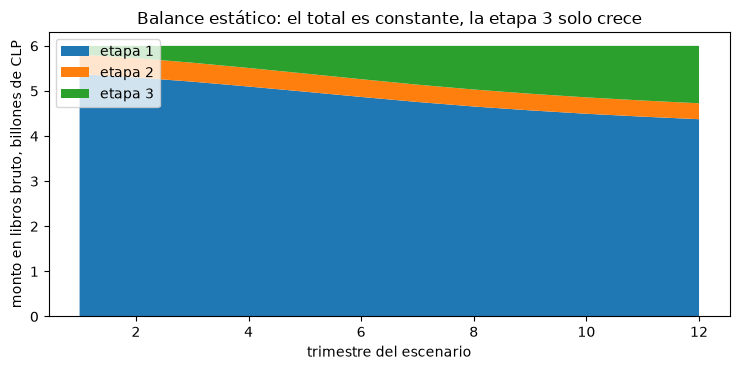

tras el trimestre 1 [5373795.  434116.  192090.] tras el trimestre 12 [4373983.  353347. 1272670.]
prueba del motor reglas violadas [] períodos 12


In [8]:
# Aplicar la regla de la etapa 3 a los doce flujos, dibujar los saldos por etapa y ejecutar la prueba del motor
balances = capital.eba_static_balance_sheet(stage_balances, flows)
tolerance = 1e-9 * float(stage_balances.sum())
result = stress_tests.static_balance_sheet_rules(balances, tolerance=tolerance)
fig, ax = plt.subplots(figsize=(7.5, 3.8))
ax.stackplot(np.arange(1, 13), balances.T / 1e6, labels=["etapa 1", "etapa 2", "etapa 3"])
ax.set_xlabel("trimestre del escenario")
ax.set_ylabel("monto en libros bruto, billones de CLP")
ax.set_title("Balance estático: el total es constante, la etapa 3 solo crece")
ax.legend(loc="upper left")
fig.tight_layout()
plt.show()
print("tras el trimestre 1", np.round(balances[0], 0), "tras el trimestre 12", np.round(balances[-1], 0))
print("prueba del motor", "reglas violadas", result.extras["violated"], "períodos", result.n)

Las tres bandas suman siempre la misma altura, el total constante, mientras la banda de la etapa 3, abajo, crece de 141.229
millones de pesos en el punto de partida a 1.272.670 millones tras doce trimestres, la suma de 1.131.441 millones de nueva
exposición de etapa 3. Las etapas 1 y 2 se reducen en proporción para pagarla. La prueba del motor no encuentra ninguna regla
violada en los doce períodos. Una prueba justifica su lugar fallando cuando debe, lo que la celda siguiente comprueba
plantando dos violaciones en copias de los saldos.

La regla se cumple en la trayectoria versionada. Una prueba se gana su lugar fallando cuando debe, así que la celda siguiente planta dos violaciones en una copia de los saldos, una cura (la etapa 3 baja en el último trimestre) y un cambio del total (se aumenta un saldo de etapa 1), y el motor nombra cada regla rota.

In [9]:
# Plantar una cura y un cambio del total en copias de los saldos y dejar que el motor nombre las reglas rotas
cured = balances.copy()
cured[-1] = cured[-1] + np.array([cured[-1, 2] * 0.1, 0.0, -cured[-1, 2] * 0.1])
inflated = balances.copy()
inflated[5, 0] += 0.01 * stage_balances.sum()
LIGHT = {"green": "verde", "red": "rojo"}
for label, planted in (("trayectoria versionada", balances), ("una cura plantada", cured),
                       ("el total cambiado", inflated)):
    test = stress_tests.static_balance_sheet_rules(planted, tolerance=tolerance)
    print(f"{label:26s} {LIGHT[test.light.value]:6s} {test.extras['violated']}")

trayectoria versionada     verde  []
una cura plantada          rojo   ['no-cure']
el total cambiado          rojo   ['constant-total']


### Paso 6: la aproximación de la guía de Pilar 2 y el formulario del Anexo 3

**Guía de Pilar 2 (P2G).** La calibración de la guía de la CMF no es pública, así que el caso declara una **aproximación de Contraste**, rotulada así y no un requerimiento de P2G: la mayor caída de CET1/APR desde el punto de partida dentro del horizonte en el estrés, menos los colchones utilizables (conservación, contracíclico y el colchón voluntario de estrés), con piso en cero,

$$\mathrm{P2G}_{\text{aprox}} = \max\!\left(0,\ \max_t\left[\left(\tfrac{\mathrm{CET1}}{\mathrm{APR}}\right)_0 - \left(\tfrac{\mathrm{CET1}}{\mathrm{APR}}\right)_t^{\text{severo}}\right] - \text{utilizable}\right).$$

**Anexo 3.** La autoevaluación de capital IAPE termina en un formulario resumen de 34 filas (CMF Circular 2.365, Anexo 3), cada una con cuatro columnas: A (porcentaje de los APR), B (monto), C (exigencia legal) y D (medición interna). `annex3_summary` construye todas las filas a partir del capital, el objetivo, los APR por riesgo, el capital interno de cada riesgo y el plan, y da a cada celda un estado: un valor, `RI` para un riesgo inmaterial, `not-to-be-filled` para riesgo de mercado y operacional bajo el método estándar, o `not-applicable`. La fila 7.2 es el requerimiento del artículo 66 quinquies, nunca la estimación propia del banco.

La celda siguiente calcula `p2g_proxy` y reconstruye todo el formulario con `annex3_summary`, con el capital interno de crédito
y de riesgo de tasa de interés tomado del capital económico versionado del notebook 01. Imprime las filas del formulario que
importan, y la única verificación de reproducción de este notebook: si las 34 filas reconstruidas son las versionadas.

In [10]:
# La aproximación de P2G, luego las 34 filas del Anexo 3 reconstruidas con el motor
severe_ratios = [y.cet1 / y.rwa for y in stress]
usable = oi.c_ccob + oi.c_ccyb + oi.c_d
proxy = capital.p2g_proxy(start["cet1_ratio"], severe_ratios, usable)
fall = max(start["cet1_ratio"] - r for r in severe_ratios)
print("mayor caída de CET1/APR", round(fall, 4), "colchones usables", round(usable, 4))
print("sustituto de P2G", proxy)
by_risk = {m["risk"]: m["ec_clp_m"] for m in fed["aggregation"]["marginals"]}
none_rows = ("concentration_individual", "concentration_sectoral", "concentration_other",
             "strategic", "reputational", "other")
internal = {"credit": by_risk["credit"], "irrbb": by_risk["irrbb"], **{name: None for name in none_rows}}
own_funds = {"cet1": start["cet1_clp_m"], "at1": start["at1_clp_m"], "t2": start["t2_clp_m"]}
form = capital.annex3_summary(own_funds, oi, start["rwa_by_risk"], internal, plan, False)
print("filas reconstruidas", len(form), "idénticas a las versionadas", list(form) == fed["annex3"]["rows"])
SHOW = {"1.3": "CET1 / RWA", "5": "OI", "7": "requerimiento mínimo de PE", "7.2": "art. 66 quinquies",
        "10.1": "estrés severo, caída de CET1", "12": "holgura sobre el OI"}
for row in form:
    if row["row_id"] in SHOW:
        value = row["a"]["value"]
        print(f"{row['row_id']:5s} {SHOW[row['row_id']]:40s} A", None if value is None else round(value, 5))

mayor caída de CET1/APR 0.0364 colchones usables 0.04
sustituto de P2G 0.0
filas reconstruidas 34 idénticas a las versionadas True
1.3   CET1 / RWA                               A 0.11
5     OI                                       A 0.145
7     requerimiento mínimo de PE               A 0.09625
7.2   art. 66 quinquies                        A 0.00125
10.1  estrés severo, caída de CET1             A 0.03644
12    holgura sobre el OI                      A 0.02394


## Resultados

La última figura pone lado a lado los dos hallazgos del plan: la holgura de la razón de patrimonio efectivo estresada sobre el
mínimo legal y sobre el objetivo propio del banco, año a año, en puntos de APR.

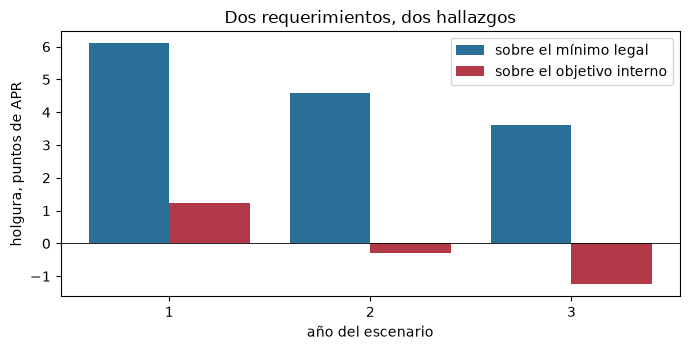

holgura sobre el mínimo legal, puntos [6.1  4.59 3.62]
holgura sobre el objetivo interno, puntos [ 1.22 -0.29 -1.25]


In [11]:
# La holgura del patrimonio efectivo estresado sobre el mínimo legal y sobre el objetivo interno
over_legal = [(y.pe_pct - legal_minimum) * 100 for y in stress]
over_target = [(y.pe_pct - oi.oi) * 100 for y in stress]
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.bar(np.arange(3) - 0.2, over_legal, width=0.4, color="#2a6f97", label="sobre el mínimo legal")
ax.bar(np.arange(3) + 0.2, over_target, width=0.4, color="#b23a48", label="sobre el objetivo interno")
ax.axhline(0, color="black", linewidth=0.6)
ax.set_xticks(np.arange(3))
ax.set_xticklabels(YEARS)
ax.set_xlabel("año del escenario")
ax.set_ylabel("holgura, puntos de APR")
ax.set_title("Dos requerimientos, dos hallazgos")
ax.legend()
fig.tight_layout()
plt.show()
print("holgura sobre el mínimo legal, puntos", np.round(over_legal, 2))
print("holgura sobre el objetivo interno, puntos", np.round(over_target, 2))

Las barras azules se mantienen muy sobre cero los tres años, 6,10; 4,59 y 3,62 puntos, mientras las rojas parten en 1,22 y
luego cruzan el cero, a menos 0,29 y menos 1,25. El sustituto de la guía de Pilar 2 es cero, porque la mayor caída de CET1
sobre APR, 3,64 puntos, es menor que los 4,0 puntos de colchones usables, así que el caso no fija guía adicional. La figura
muestra que la respuesta a una prueba de estrés depende del requerimiento con que se lea; no dice cuál de los dos usaría el
supervisor para actuar, que es una pregunta de la regulación y no de la aritmética.

**Respuesta:** sí frente al mínimo legal y no frente al objetivo propio del banco. Bajo el escenario severamente adverso de la
Reserva Federal la razón de patrimonio efectivo de Banco Andino es 15,72; 14,21 y 13,25 por ciento en los tres años, siempre
sobre el mínimo legal de 9,625 por ciento, con una holgura de 6,10; 4,59 y 3,62 puntos y sin déficit, pero queda 1,22 puntos
sobre el objetivo interno de 14,5 por ciento en el año 1 y 0,29 y 1,25 puntos bajo él en los años 2 y 3. La razón CET1 solo con
pérdidas cae de 11,00 a 9,83; 8,32 y 7,36 por ciento de los APR tras pérdidas estresadas de 87.706; 113.174 y 72.193 millones
de pesos, y la fila etiquetada de PPNR, 147.813 y 147.070 millones al año, la subiría a 11,80; 12,25 y 13,25 por ciento. Las 34
filas del formulario del Anexo 3 reconstruidas con el motor son las versionadas.

Lo que este notebook no muestra: el NII detrás del PPNR se leyó y no se recalculó, porque necesita la cartera de tasas de
interés del caso C15; el capital y los APR son anclas de un banco sintético, así que ninguna de estas razones describe un banco
real; y la pérdida estresada es un piso, porque los riesgos de mercado y operacional llevan solo su pérdida esperada en todo
escenario.

## Resumen

- La trayectoria de CET1 principal es el CET1 inicial menos las pérdidas con estrés acumuladas, sin inventar ingresos; el PPNR es una fila rotulada con dos razones declaradas.
- El objetivo interno OI suma el mínimo de 8 por ciento, los colchones, la estimación propia de Pilar 2 del banco y un colchón voluntario; el tope de 4 por ciento limita el requerimiento del artículo 66 quinquies, nunca la estimación propia, y el motor rechaza ambos errores.
- `capital_plan` corre base, estrés y estrés con mitigación sobre un balance estático; en el escenario severamente adverso el mínimo legal se mantiene en todos los años y el objetivo interno no.
- Las reglas de balance estático de la EBA (total constante, nada sale de la etapa 3) las aplica `eba_static_balance_sheet` y las comprueba una prueba que nombra una cura plantada y un total cambiado.
- La cifra de P2G es una aproximación rotulada de Contraste, y las 34 filas del Anexo 3 reconstruidas con el motor son idénticas a las versionadas.

**Qué probar a continuación.** Cambia `c_d`, el colchón voluntario, a cero en el paso 3 y mira cómo se mueven el objetivo interno y su holgura; luego sigue con el notebook 06, que hace la pregunta inversa: qué escenario llevaría al banco al mínimo legal.

## Referencias

- EBA (2025), 2025 EU-wide stress test, Methodological Note del 2025-01-20: el balance estático (párrafos 24, 33, 34 y 90 a 92). https://www.eba.europa.eu/sites/default/files/2025-01/0246e2f3-fa57-47d1-99f2-7a5b80cae509/2025%20EU-wide%20stress%20test%20-%20Methodological%20Note.pdf
- CMF Chile (2025), Circular 2.365 y Anexo 3 del autoevaluación de capital (IAPE), el formulario resumen de 34 filas. https://www.cmfchile.cl/portal/principal/623/articles-29808_doc_pdf.pdf
- Dossier 03 de la investigación persistida de Contraste (la pila de capital chilena en 2026, el objetivo interno de capital y las pruebas de estrés dentro del IAPE), resumido en la base de investigación del SDD.
- Este repositorio: `docs/contracts/engine/stress-api.md` (el motor de capital) y `docs/design/features/c18/design.md`.